# 02 · Is there a lead-lag signal? (go/no-go)

Before any model: do the leaders' **past** returns say anything about ICHR's **next-hour** return?
If not even a correlation shows up, an LSTM is fitting noise.

Setup: at the close of bar *t* we know every return up to and including bar *t*.
Target `y_t` = ICHR's log return in bar *t+1*. Predictor at lag *k* = ticker X's return in bar *t−k*.
So *k = 0* means "the hour that just ended".

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from semiconductor_affairs.data import FIRST_BAR, bar_start, load_close, log_returns
from semiconductor_affairs.ingest import TARGET

r = log_returns(load_close())
hour = pd.Series(bar_start(r.index), index=r.index)

y = r[TARGET].shift(-1)          # ICHR return in the next bar
y_hour = hour.shift(-1)          # which bar of the day that is
intraday = (y_hour != FIRST_BAR) & y.notna()   # exclude overnight-gap targets
overnight = y_hour == FIRST_BAR
print(f"intraday targets: {intraday.sum()},  overnight targets: {overnight.sum()}")

intraday targets: 4343,  overnight targets: 728


## How big must a correlation be to mean anything?

Even if ICHR's next hour had **nothing** to do with LRCX, the correlation over a few thousand hours wouldn't come out
as exactly 0. It wobbles around 0 by chance, and the more samples, the smaller the wobble (about 1/√N).

- With N ≈ 4,300 hours, 95% of pure-noise correlations land within **±0.030**: the *noise band*.
- So a single cell outside ±0.030 has only a 5% chance of being luck.
- **But** the heatmap has 70 cells. 5% of 70 ≈ 3.5, so **~3–4 bold cells are expected even if there's no signal at all.**
  Like flipping 70 coins: some streaks are guaranteed.


In [2]:
def noise_band(n):
    return 1.96 / np.sqrt(n)

print(f"noise band: ±{noise_band(intraday.sum()):.3f}")

noise band: ±0.030


## 1. Lagged correlation heatmap (intraday)

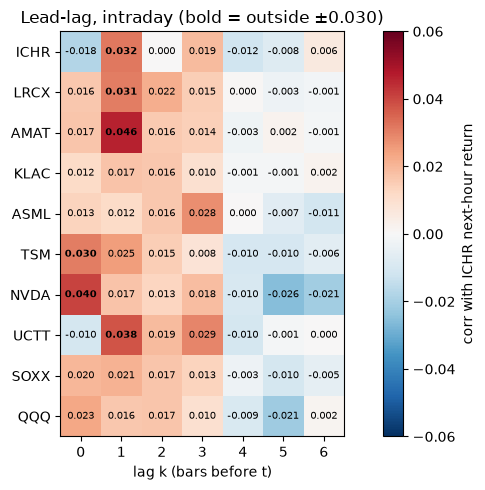

In [3]:
LAGS = range(7)
lead = pd.DataFrame(
    {k: r.shift(k)[intraday].corrwith(y[intraday]) for k in LAGS}
)
lead.columns.name = "lag k"

band = noise_band(intraday.sum())
fig, ax = plt.subplots(figsize=(8, 5))
lim = 0.06
im = ax.imshow(lead, cmap="RdBu_r", vmin=-lim, vmax=lim)
ax.set_xticks(range(len(LAGS)), LAGS)
ax.set_yticks(range(len(lead)), lead.index)
ax.set_xlabel("lag k (bars before t)")
for i in range(lead.shape[0]):
    for j in range(lead.shape[1]):
        v = lead.iat[i, j]
        ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=7,
                fontweight="bold" if abs(v) > band else "normal")
fig.colorbar(im, label="corr with ICHR next-hour return")
ax.set_title(f"Lead-lag, intraday (bold = outside ±{band:.3f})")
plt.tight_layout()

### What does pure noise look like?
Shuffle ICHR's next-hour returns randomly. That destroys any real link with the past, but keeps everything else
(including how the tickers move together). Then count the bold cells. Repeat 1,000 times.

In [ ]:
X = pd.concat({k: r.shift(k)[intraday] for k in LAGS}, axis=1).fillna(0).to_numpy()
X = (X - X.mean(0)) / X.std(0)
target = y[intraday].to_numpy()
rng = np.random.default_rng(0)

n_bold = []
for _ in range(1000):
    shuffled = rng.permutation(target)
    shuffled = (shuffled - shuffled.mean()) / shuffled.std()
    corr = X.T @ shuffled / len(shuffled)   # correlation of every cell at once
    n_bold.append((np.abs(corr) > band).sum())
n_bold = np.array(n_bold)

real_bold = (lead.abs() > band).to_numpy().sum()
plt.hist(n_bold, bins=range(n_bold.max() + 2), align="left")
plt.axvline(real_bold, color="r", label=f"real data: {real_bold}")
plt.xlabel("bold cells in a shuffled heatmap"); plt.ylabel("count"); plt.legend()
print(f"noise gives {n_bold.mean():.1f} bold cells on average; "
      f"{(n_bold >= real_bold).mean():.0%} of shuffles give ≥ {real_bold}")

**Takeaway:** the real heatmap has 6 bold cells. Noise gives 3.6 on average, but **≥ 6 in about 1 in 4 shuffles**.
The tail is long because the tickers move together: when chance lines one of them up with ICHR, its peers line up too,
so false alarms come in clumps. **The heatmap on its own isn't convincing evidence of a lead-lag signal.**

## 2. Direction check: who leads whom?

A correlation between "X now" and "ICHR next hour" could also mean they just react to the same news at slightly
different speeds, with neither one leading. So we check **both directions** (lag 0, intraday):

- **X leads ICHR** = corr(X's return this hour, ICHR's return *next* hour)
- **ICHR leads X** = corr(ICHR's return this hour, X's return *next* hour)

If ICHR really is the *last* to respond, the first column should be clearly positive and the second close to 0.
If both are about equal, there's no "late follower", just a general echo between the stocks.

In [4]:
forward = r[intraday].corrwith(y[intraday])                       # X_t -> ICHR_{t+1}
reverse = pd.Series({c: r[TARGET][intraday].corr(r[c].shift(-1)[intraday]) for c in r})  # ICHR_t -> X_{t+1}
pd.DataFrame({"X leads ICHR": forward, "ICHR leads X": reverse}).round(3)

,X leads ICHR,ICHR leads X
ICHR,-0.018,-0.018
LRCX,0.016,0.017
AMAT,0.017,0.021
KLAC,0.012,0.033
ASML,0.013,0.025
TSM,0.030,0.006
NVDA,0.040,-0.016
UCTT,-0.010,0.021
SOXX,0.020,0.022
QQQ,0.023,-0.009


**What it shows**

- **Equipment stocks (LRCX, AMAT, KLAC, ASML, UCTT) and SOXX:** both columns are about equal, or ICHR leading is even
  slightly stronger. So **ICHR doesn't lag its own customers.**
- **TSM, NVDA, QQQ:** the only one-way pattern (e.g. NVDA 0.040 vs −0.016). The *AI demand / big tech* side seems to
  lead and ICHR follows, not the other way round.
- **ICHR row:** identical in both columns by construction (it's ICHR vs itself).
- **Caveat:** all values are around the ±0.030 noise band, so this is a hint, not proof.

**For the hypothesis:** the "customers lead, supplier follows" story isn't supported. If anything, the signal flows
from end demand (Nvidia, TSMC, the market) to the small cap. The LSTM should keep those inputs.

## 3. Stability: is it the same every year?

The heatmap averages over ~3 years. An average of +0.03 could mean "a small effect that's always there" (useful) or
"a big positive year plus a big negative year" (useless for predicting). So we compute the lag-0 correlation **per year**.

Fewer samples per year means a wider noise band: about ±0.052 with ~1,400 hours per year.
The data starts on 2023-12-26, so 2023 has only a few days. We drop it, because with ~20 hours the band is about ±0.4.

In [5]:
n_per_year = r[intraday].index.year.value_counts().sort_index()
print("intraday hours per year:", n_per_year.to_dict())
years = [yr for yr, n in n_per_year.items() if n >= 500]   # skip the 2023 stub

by_year = pd.DataFrame({
    yr: r[intraday & (r.index.year == yr)].corrwith(y[intraday & (r.index.year == yr)])
    for yr in years
})
print(f"noise band per year ≈ ±{noise_band(n_per_year[years].min()):.3f}")
by_year.round(3)

noise band per year ≈ ±0.052


,2023,2024,2025,2026
ICHR,0.132,-0.010,0.031,-0.061
LRCX,0.106,0.041,0.086,-0.035
AMAT,0.038,0.056,0.091,-0.043
KLAC,0.020,0.048,0.085,-0.046
ASML,-0.030,0.045,0.093,-0.060
TSM,-0.022,0.042,0.116,-0.048
NVDA,0.006,0.022,0.080,0.018
UCTT,0.139,0.027,0.046,-0.058
SOXX,0.076,0.039,0.093,-0.037
QQQ,0.034,0.007,0.110,-0.052


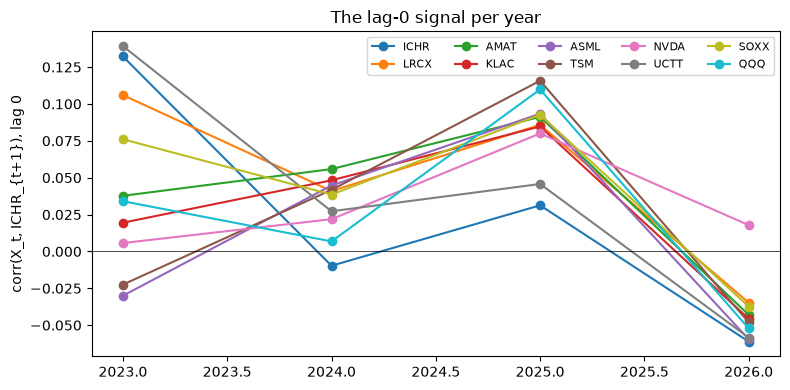

In [6]:
ax = by_year.T.plot(marker="o", figsize=(8, 4))
ax.axhline(0, color="k", lw=0.5)
ax.set_ylabel("corr(X_t, ICHR_{t+1}), lag 0")
ax.legend(ncol=5, fontsize=8)
ax.set_title("The lag-0 signal per year")
plt.tight_layout()

**What it shows**

- **2024:** small positive values (0.01–0.06), almost all inside the ±0.052 band. Basically nothing.
- **2025:** *everything* is positive and mostly outside the band (0.05–0.12), **including QQQ (0.110)**. QQQ is the
  whole tech market, not ICHR's supply chain. So in 2025 the pattern was "whatever the market did last hour, ICHR
  continued next hour": **market-wide momentum**, not a supplier lagging its customers.
- **2026:** almost everything flips **negative** (−0.04 to −0.06): last hour's move tends to *reverse*. Only NVDA
  stays slightly positive.
- **The 3-year average (~+0.02) hides this:** it's +0.09 in one year and −0.05 in another, averaged out.

**Why this matters for modelling**

A model trained on 2024–2025 would learn "follow the last hour", and **lose money in 2026**, where the opposite holds.
So: evaluate per year / walk-forward (train on the past, test on the next period, roll forward), consider retraining
regularly, and be suspicious of any result that only holds in one year.

## 4. Overnight: does the last hour predict the overnight gap?

Sections 1–3 left out the first bar of the day. Here we look **only** at it:

- **Predictor:** X's return in the **last bar of the day** (15:30–16:00 New York).
- **Target:** ICHR's return in the **first bar of the next day**, from yesterday's close to the close of the
  09:30–10:30 bar. That contains the overnight gap (news, earnings, Asia and Europe trading while the US is closed)
  plus the first hour of trading.

Only ~730 such nights, so the noise band is wider: ±0.073.

In [7]:
print(f"noise band: ±{noise_band(overnight.sum()):.3f}")
r[overnight].corrwith(y[overnight]).round(3)

noise band: ±0.073


ICHR   -0.132
LRCX   -0.091
AMAT   -0.096
KLAC   -0.092
ASML   -0.069
TSM    -0.061
NVDA   -0.031
UCTT   -0.072
SOXX   -0.106
QQQ    -0.069
dtype: float64

### Split: the gap itself vs the first hour
The 09:30 bar's **open** price lets us separate the two parts:
`gap = log(open / yesterday's close)` and `first hour = log(close / open)`.

In [ ]:
from semiconductor_affairs.ingest import DATA_DIR

ichr = pd.read_parquet(DATA_DIR / f"{TARGET}.parquet")
gap = np.log(ichr["open"] / ichr["close"].shift(1)).reindex(r.index).shift(-1)
first_hour = np.log(ichr["close"] / ichr["open"]).reindex(r.index).shift(-1)

pd.DataFrame({
    "full first bar": r[overnight].corrwith(y[overnight]),
    "gap only": r[overnight].corrwith(gap[overnight]),
    "first hour only": r[overnight].corrwith(first_hour[overnight]),
}).round(3)

In [ ]:
print(f"noise band per year ≈ ±{noise_band(overnight.sum() / 3):.3f}")
pd.DataFrame({
    yr: r[overnight & (r.index.year == yr)].corrwith(y[overnight & (r.index.year == yr)])
    for yr in years
}).round(3)

**What it shows**

- **Every ticker is negative.** A move in the last hour tends to *partly reverse* overnight. ICHR (−0.13), SOXX (−0.11),
  AMAT, KLAC and LRCX (≈ −0.09) are outside the ±0.073 band.
- **It's mostly in the gap itself**, not the first trading hour.
- **It holds every year** (2024, 2025 and 2026 all negative), unlike the intraday signal in section 3, which flipped.
  Each single year is inside its wide band (±0.12), but the same sign in 3 of 3 years for all tickers is hard to get by chance.
- **Not just a data artefact.** ICHR vs *itself* could partly be bid-ask bounce: its thinly traded closing price randomly
  lands on the buy or sell side and snaps back. But SOXX is one of the most liquid ETFs, and *its* last hour predicts
  ICHR's gap too. That points to a real market effect, e.g. end-of-day order flows that push prices temporarily.

**For the project:** this is the most consistent pattern so far, and it's in exactly the bar we excluded from v1.
Keep the v1 exclusion (the first bar behaves differently), but treat "predict the overnight gap" as a separate
experiment later. With ~730 nights it's a small-data problem, so a simple model will likely beat an LSTM there.

## 5. Event study: after a *big* move in a leader

A correlation averages over **all** hours, and most hours are just small noise. Maybe the leaders only matter when
something big happens (a news hour), and are irrelevant otherwise. A linear model can't express "only matters when big".
An LSTM can, which is exactly what it would have to offer.

How we check:
- **Big move** = a leader's hourly return more than 2σ or 3σ from normal (σ = its typical hourly move).
  2σ ≈ 4% of hours, 3σ ≈ 1%.
- For each such hour, look at ICHR's return in the **next** hour, and average separately after up and down moves.
- Compare with the normal next-hour average: +0.014%.
- **± 1 s.e.** (standard error) = how uncertain that average is: ICHR's hourly spread (~1%) / √n.
  An average less than ~2 s.e. from zero could easily be chance.

In [8]:
base = intraday & (hour != FIRST_BAR)   # predictor bar is intraday too
rows = []
for c in ["LRCX", "AMAT", "NVDA", "TSM", "SOXX"]:
    z = r[c] / r[c][base].std()
    for th in [2, 3]:
        for side, m in [("up", base & (z > th)), ("down", base & (z < -th))]:
            rows.append({"leader": c, "threshold σ": th, "move": side, "n": m.sum(),
                         "ICHR next hour %": y[m].mean() * 100,
                         "± 1 s.e.": y[m].std() / np.sqrt(m.sum()) * 100})
events = pd.DataFrame(rows).round(3)
print(f"unconditional ICHR next hour: {y[base].mean()*100:+.3f}%")
events

unconditional ICHR next hour: +0.014%


,leader,threshold σ,move,n,ICHR next hour %,± 1 s.e.
0,LRCX,2,up,79,0.330,0.209
1,LRCX,2,down,97,0.113,0.174
2,LRCX,3,up,22,0.691,0.558
3,LRCX,3,down,35,0.318,0.352
4,AMAT,2,up,73,0.285,0.227
5,AMAT,2,down,106,-0.026,0.153
6,AMAT,3,up,22,0.604,0.588
7,AMAT,3,down,35,0.259,0.379
8,NVDA,2,up,78,0.338,0.190
9,NVDA,2,down,105,-0.145,0.105


**What it shows**

- **The direction is suggestive:** after a big *up* hour in any leader, ICHR's next hour is positive in all 10 rows
  (+0.13% to +0.69%). After big *down* hours in NVDA and TSM, ICHR tends to drop too.
- **But none of it is clearly beyond chance.** Few events (n ≈ 20–100) and a noisy ICHR mean wide error bars: the best
  row, NVDA >2σ up, is +0.34% ± 0.19%, under 2 s.e. The eye-catching >3σ rows (+0.6–0.7%) have s.e. ≈ 0.5–0.65%,
  roughly 1 s.e. from zero.
- **Averages are pulled by a few large hours:** the typical (median) next hour is only about ±0.1–0.2%, and ICHR goes up
  after a big leader up-move only ~56–60% of the time.
- **The rows aren't independent:** LRCX, AMAT and SOXX usually jump in the *same* hour, so they count the same events
  several times. That's 20 rows, not 20 independent tests.
- **Down moves are mixed:** after big LRCX/AMAT/SOXX drops, ICHR's next hour is around zero or even slightly positive,
  but well within the error bars.

**For the project:** "big moves matter more" is a plausible hint, not a finding. It's still worth testing,
because it's the kind of conditional pattern a linear model can't capture. Concretely, step 3 gives the ridge
baseline a "big move" input, so an LSTM win can't come only from seeing big moves.

## 6. Excess return as target
Strip the sector: `ICHR − β·SOXX`, with β from a rolling 140-bar (~4 week) window, using only past data.

In [9]:
beta = (r[TARGET].rolling(140).cov(r["SOXX"]) / r["SOXX"].rolling(140).var()).shift(1)
excess_next = (r[TARGET] - beta * r["SOXX"]).shift(-1)
m = intraday & excess_next.notna()
pd.DataFrame({
    "all": r[m].corrwith(excess_next[m]),
    **{yr: r[m & (r.index.year == yr)].corrwith(excess_next[m & (r.index.year == yr)])
       for yr in years},
}).round(3)

,all,2023,2024,2025,2026
ICHR,-0.044,NaN,-0.049,-0.030,-0.056
LRCX,0.009,NaN,0.008,0.060,-0.024
AMAT,-0.002,NaN,0.017,0.052,-0.044
KLAC,-0.007,NaN,-0.001,0.042,-0.041
ASML,-0.004,NaN,-0.001,0.062,-0.058
TSM,0.011,NaN,0.014,0.068,-0.044
NVDA,0.039,NaN,0.027,0.057,0.033
UCTT,-0.023,NaN,0.013,0.007,-0.057
SOXX,0.001,NaN,-0.003,0.059,-0.041
QQQ,0.017,NaN,-0.010,0.085,-0.039


## Conclusions (2026-11-19)

1. **The linear lead-lag signal is weak.** Best intraday correlations are ~0.03–0.05 (AMAT/UCTT/ICHR at lag 1, NVDA at lag 0),
   just outside the ±0.030 noise band, with ~70 pairs tested. Everything is gone by lag 4.
2. **It isn't stable.** 2025 shows a real signal (~0.08–0.11 at lag 0), 2024 a small one, and 2026 has the *opposite* sign.
   QQQ predicts as well as ICHR's own customers, so 2025 looks like broad market momentum, not supply-chain lag.
3. **No clear direction.** ICHR "predicts" the leaders about as well as they predict ICHR. There's no evidence ICHR is
   specifically the late one.
4. **Overnight reversal.** The last hour's move is negatively related to the overnight gap (ICHR itself −0.13, SOXX −0.11,
   band ±0.073). Part of ICHR's own reversal is likely bid-ask bounce from thin trading.
5. **Big moves: a hint, not a finding.** After a >2σ up hour in a leader, ICHR's next hour averages +0.1% to +0.3%
   (vs +0.01% normally), and more after >3σ hours, but every row is within ~2 standard errors of zero, and medians are small.
6. **Excess-return target:** same picture, again carried by 2025.

**Decision: go, with tempered expectations.** There's no robust linear edge, but there are weak hints of nonlinear, regime-dependent
behaviour, which is a fair test for an LSTM vs ridge. The learning goal doesn't depend on finding alpha.
Consequences for step 3: exclude the overnight bar from the v1 target, evaluate **per year / walk-forward**,
and add a big-move feature to the baselines so the LSTM's advantage isn't just "it saw the big moves".